## **Part I**: EDA & Network Graph Logic

---
---

#### This Part contains all the following:

- All Required Libraries Imports
- Loading Data Tables, ERD, and understand them
- Performing all needed EDA for each table of our data
- Apply Feature Engineering for some columns
- Applying The Graph Engine Logic and Analysis on the prerequisites table
- Concluding a Formula to calculate CLS (Cirruclum Laverage Score) to know the normalized importance score for each course

This section imports all libraries required

In [ ]:
# ─────────────────────────────────────────────────────────────
# STANDARD LIBRARY IMPORTS - Each with purpose explanation
# ─────────────────────────────────────────────────────────────
import os                  # Operating system interface - file paths, environment variables
import json                # JSON handling - critical for Gemini LLM responses and MCQ questions
import re                  # Regular expressions - text cleaning and pattern matching in syllabus
import warnings            # Warning control - suppresses unnecessary library warnings
from pathlib import Path   # Modern file path handling - cleaner than os.path
import collections         # Import the base collections module (where the outdated code expects to find MutableSet)
import collections.abc     # Import the abstract base classes module (where Python 3.10+ actually stores MutableSet)
collections.MutableSet = collections.abc.MutableSet     # Monkey patch MutableSet into the collections module
import streamlit as st     # we can safely import Streamlit without triggering the AttributeError
import base64              # Binary to text encoding - useful for file previews or embeddings
warnings.filterwarnings("ignore")  # Hide annoying warnings from pandas, PyPDF2, etc.
from typing import Optional


# ─────────────────────────────────────────────────────────────
# DATA HANDLING LIBRARIES
# ─────────────────────────────────────────────────────────────
import pandas as pd        # Data manipulation and analysis - core for courses, students, history
import numpy as np         # Numerical operations - used in calculations and weights
import datetime


# ─────────────────────────────────────────────────────────────
# VISUALIZATION LIBRARIES
# ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt 
import seaborn as sns 
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white"}) 
sns.set_theme(style="whitegrid", palette="muted")


# ─────────────────────────────────────────────────────────────
# GRAPH_THEORY LIBRARY
# ─────────────────────────────────────────────────────────────
import networkx as nx      # Directed graph to model prerequisite chains


# ─────────────────────────────────────────────────────────────
# LLM GEMINI IMPORT & AI CLIENT INITIALIZATION
# ─────────────────────────────────────────────────────────────
from google import genai
API_KEY = os.environ.get("GEMINI_API_KEY")   # Not hard-codes for security
client = genai.Client(api_key = API_KEY)     # Initialize the client (it automatically picks up the GEMINI_API_KEY environment variable)
DEFAULT_MODEL = "gemini-2.5-flash"           # Use the recommended, fast model for general text tasks

# Define a global helper function to make prompts easy anywhere in the notebook
def llm(prompt: str, model_name: str = DEFAULT_MODEL) -> str:    
    try:
        response = client.models.generate_content(
            model=model_name,
            contents=prompt,
        )
        return response.text
    except Exception as e:
        return f"An error occurred: {str(e)}"


# ─────────────────────────────────────────────────────────────
# SYLLABUS FILE PARSING
# ─────────────────────────────────────────────────────────────
import pdfplumber               # PDF text extraction (preserves layout)
from pptx import Presentation   # PowerPoint (.pptx) reading
import docx                     # Word (.docx) reading


# ─────────────────────────────────────────────────────────────
# PDF GENERATION FOR DOWNLOADABLE NOTES
# ─────────────────────────────────────────────────────────────
from fpdf import FPDF       # fpdf2: multi-page PDF creation


print("✓ Libraries imported and Gemini Client initialized successfully!")

✓ Libraries imported and Gemini Client initialized successfully!


------------------------------------

### General Functions and Calculations used in thid NoteBook

In [11]:
def min_max_normalize(series):
    return (series - series.min()) / (series.max() - series.min())


def get_grade(score):
    if score >= 85:
        return 'Excellent'
    elif score >= 75:
        return 'Very Good'
    elif score >= 65:
        return 'Good'
    elif score >= 60:
        return 'Pass'
    else:
        return 'Fail'

print("✓ All Functions are working successfully")

✓ All Functions are working successfully


-----------------------

### Load Dataset

In [12]:
courses = pd.read_csv("Data\Courses.csv")
students = pd.read_csv("Data\Students.csv")
history = pd.read_excel("Data\Student_Course_History.xlsx")
prerequisites = pd.read_excel("Data\Prerequisites.xlsx")
print("✓ All Datasets uploaded successfully! ")

✓ All Datasets uploaded successfully! 


-----------------

### Database Schema & Relationships (ERD Summary)

The database consists of **4 main tables** with the following relationships:

#### 1. Tables Overview

| Table Name              | Description                          | Primary Key          |
|-------------------------|--------------------------------------|----------------------|
| **Courses**             | All courses offered by the university | `course_id`          |
| **Prerequisites**       | Prerequisite relationships between courses | `prerequisite_id` |
| **Students**            | Student personal and academic info   | `student_id`         |
| **Student_Course_History** | Record of every course taken by each student | `history_id` |



#### 2. Relationships (Simple Explanation)

##### **Courses ↔ Prerequisites** (One-to-Many)
- One course **can have** multiple prerequisites.
- A course **can be** a prerequisite for multiple other courses.
- **Foreign Keys**:
  - `Prerequisites.course_id` → `Courses.course_id`
  - `Prerequisites.required_course_id` → `Courses.course_id`

##### **Courses ↔ Student_Course_History** (One-to-Many)
- One course **can be taken** by many students (across different semesters/years).
- **Foreign Key**: `Student_Course_History.course_id` → `Courses.course_id`

##### **Students ↔ Student_Course_History** (One-to-Many)
- One student **can take** many courses (their academic history).
- **Foreign Key**: `Student_Course_History.student_id` → `Students.student_id`

##### **Students ↔ Courses** (Indirect / Many-to-Many)
- Through the `Student_Course_History` table (this is the junction table).
- This allows tracking which students took which courses and their scores.



#### 3. Visual Relationship Summary


![ERD Diagram](Data\ERD.jpg)

- **Students** are connected to their performance via **Student_Course_History**.
- **Courses** are connected to their prerequisites via **Prerequisites** table.
- **No direct link** between Students and Prerequisites (you need to go through history + courses).


#### 4. Key Notes

- **Total Students**: 500
- **Total Courses**: 85
- **History Records**: 11984 
- The `Student_Course_History` is the **largest** and most important table for analysis (contains grades).
- `Prerequisites` helps in building course dependency graphs or recommending courses.

-----------------------------
### Now performing EDA & Needed Feature Engineering for each table
-----------------------------

#### 1. for the students table

In [13]:
print(f"Dataset Shape: {students.shape}")
students.head().style.hide(axis="index")

Dataset Shape: (500, 6)


student_id,student_name,student_level,student_program,CGPA,total_failed_subjects
1,Abdelrahman Ahmed,4,Statistics and Computer Science,3.900000,0
2,Hossam Hamdy,2,Mathematics,2.400000,2
3,Salma Elmongy,2,Statistics and Computer Science,3.100000,0
4,Farouk Ahmed,3,Statistics and Computer Science,1.700000,5
5,Hend Magdy,4,Mathematics,1.100000,9


In [14]:
print("Duplicate Rows:", students.duplicated().sum())
print("Students Table Summary: \n")
students.info()

Duplicate Rows: 0
Students Table Summary: 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             500 non-null    int64  
 1   student_name           500 non-null    object 
 2   student_level          500 non-null    int64  
 3   student_program        500 non-null    object 
 4   CGPA                   500 non-null    float64
 5   total_failed_subjects  500 non-null    int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 23.6+ KB


In [15]:
print("Students Table Statistics: \n")
students.describe()

Students Table Statistics: 



,student_id,student_level,CGPA,total_failed_subjects
count,500.000000,500.000000,500.00000,500.000000
mean,250.500000,2.368000,2.22548,1.240000
std,144.481833,1.109522,0.85775,2.155851
min,1.000000,1.000000,0.10000,0.000000
25%,125.750000,1.000000,1.61500,0.000000
50%,250.500000,2.000000,2.15500,0.000000
75%,375.250000,3.000000,2.85000,1.000000
max,500.000000,4.000000,4.84000,13.000000


- Our data table includes students of:
    - Different academic performance (due to CGPA & total_failed_subjects)
    - Only 2 programs included: Mathematics & Computer Science
    - All levels (academically) from 1 to 4

#### 2. for the history table

In [16]:
print(f"Dataset Shape: {history.shape}")
history.head().style.hide(axis="index")

Dataset Shape: (11984, 6)


history_id,student_id,course_id,course_code,year_taken,student_score
1,1,3,P101,2023,80
2,1,4,P102,2023,79
3,1,5,C102,2023,79
4,1,6,G101,2023,74
5,1,10,P103,2023,83


In [17]:
print("Duplicate Rows:", history.duplicated().sum())
print("Students Table Summary: \n")
history.info()

Duplicate Rows: 0
Students Table Summary: 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11984 entries, 0 to 11983
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   history_id     11984 non-null  int64 
 1   student_id     11984 non-null  int64 
 2   course_id      11984 non-null  int64 
 3   course_code    11984 non-null  object
 4   year_taken     11984 non-null  int64 
 5   student_score  11984 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 561.9+ KB


In [18]:
print("Student_Course_History Table Statistics: \n")
history.describe()

Student_Course_History Table Statistics: 



,history_id,student_id,course_id,year_taken,student_score
count,11984.000000,11984.000000,11984.000000,11984.000000,11984.000000
mean,5992.500000,247.613485,33.360564,2025.142190,72.855224
std,3459.627148,146.733421,26.340492,0.943877,13.702998
min,1.000000,1.000000,1.000000,2023.000000,27.000000
25%,2996.750000,120.000000,10.000000,2025.000000,63.000000
50%,5992.500000,240.000000,24.000000,2025.000000,74.000000
75%,8988.250000,381.000000,60.000000,2026.000000,83.000000
max,11984.000000,500.000000,85.000000,2026.000000,100.000000


##### Data included in our table is from 2023 to 2026 for all students and all courses

### Official Grading Scale (From Board Rules)

| التقدير (Arabic)     | Symbol | Points          | Percentage Range          | English Equivalent     |
|-----------------------|--------|-----------------|---------------------------|------------------------|
| ممتاز                | أ      | 3.5 - 5.0      | 85% - 100%               | Excellent             |
| جيد جداً             | ب      | 2.5 - <3.5     | 75% - <85%               | Very Good             |
| جيد                  | ج      | 1.5 - <2.5     | 65% - <75%               | Good                  |
| مقبول                | د      | 1.0 - <1.5     | 60% - <65%               | Acceptable / Pass     |
| راسب                 | ر      | 0              | <60%                     | Fail                  |
| غائب                 | غ      | 0              | -                        | Absent                |
| غير مكتمل            | غ م    | 0              | -                        | Incomplete            |
| منسحب                | من     | 0              | -                        | Withdrawn             |
| محروم                | مح     | 0              | -                        | Banned from Exam      |

In [19]:
# Adding new column "grade" based on the student_score
# we used the predefined get_grade function
history['grade'] = history['student_score'].apply(get_grade)

# Add another new column "pass" with Boolean value to use later in our Rule Based Logic System
# pass column: True if student_score >= 60, False otherwise
history['pass'] = history['student_score'] >= 60

# Viewing the table with the 2 new added columns "grade" & "pass"
history.head().style.hide(axis="index")

history_id,student_id,course_id,course_code,year_taken,student_score,grade,pass
1,1,3,P101,2023,80,Very Good,True
2,1,4,P102,2023,79,Very Good,True
3,1,5,C102,2023,79,Very Good,True
4,1,6,G101,2023,74,Good,True
5,1,10,P103,2023,83,Very Good,True


#### 3. for the courses table

In [20]:
print(f"Dataset Shape: {courses.shape}")
courses.head().style.hide(axis="index")

Dataset Shape: (85, 9)


course_id,course_code,course_name,course_program,course_level,credit_hours,semester_number,type,affects_gpa
1,M111,Calculus 1,Mathematics,1,3,1,Required,True
2,M121,Mechanics 1,Mathematics,1,3,1,Required,True
3,P101,Properties of Heat and Matter,General,1,3,1,Required,True
4,P102,"Electricity, Magnetism and Light",General,1,3,1,Required,True
5,C102,General Chemistry 2,General,1,3,1,Required,True


In [21]:
print("Duplicate Rows:", courses.duplicated().sum())
print("Courses Table Summary: \n")
courses.info()

Duplicate Rows: 0
Courses Table Summary: 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   course_id        85 non-null     int64 
 1   course_code      85 non-null     object
 2   course_name      85 non-null     object
 3   course_program   85 non-null     object
 4   course_level     85 non-null     int64 
 5   credit_hours     85 non-null     int64 
 6   semester_number  85 non-null     int64 
 7   type             85 non-null     object
 8   affects_gpa      85 non-null     bool  
dtypes: bool(1), int64(4), object(4)
memory usage: 5.5+ KB


In [22]:
print("Courses Table Statistics: \n")
courses.describe()

Courses Table Statistics: 



,course_id,course_level,credit_hours,semester_number
count,85.000000,85.000000,85.000000,85.000000
mean,43.000000,2.823529,2.482353,5.152941
std,24.681302,1.037126,0.502654,2.129755
min,1.000000,1.000000,2.000000,1.000000
25%,22.000000,2.000000,2.000000,4.000000
50%,43.000000,3.000000,2.000000,5.000000
75%,64.000000,4.000000,3.000000,7.000000
max,85.000000,4.000000,3.000000,8.000000


In [23]:
# Getting minimum & maximum credit hours from table statics
min_chours = 2
max_chours = 3

# Adding new Normalized credit hours column to use later in our calculations
courses["credit_score"] = min_max_normalize(courses["credit_hours"])

# Viewing the table with the new added column "credit_score"
courses.head().style.hide(axis="index")

course_id,course_code,course_name,course_program,course_level,credit_hours,semester_number,type,affects_gpa,credit_score
1,M111,Calculus 1,Mathematics,1,3,1,Required,True,1.000000
2,M121,Mechanics 1,Mathematics,1,3,1,Required,True,1.000000
3,P101,Properties of Heat and Matter,General,1,3,1,Required,True,1.000000
4,P102,"Electricity, Magnetism and Light",General,1,3,1,Required,True,1.000000
5,C102,General Chemistry 2,General,1,3,1,Required,True,1.000000


In [24]:
# Now encoding affect_gpa into new column as 0 if False, or 1 if True
courses["gpa_score"] = courses["affects_gpa"].astype(int)

# Showing the new added encoded column (will need it later in our calculations)
print(f"Dataset Shape: {courses.shape}")
courses.head().style.hide(axis="index")

Dataset Shape: (85, 11)


course_id,course_code,course_name,course_program,course_level,credit_hours,semester_number,type,affects_gpa,credit_score,gpa_score
1,M111,Calculus 1,Mathematics,1,3,1,Required,True,1.000000,1
2,M121,Mechanics 1,Mathematics,1,3,1,Required,True,1.000000,1
3,P101,Properties of Heat and Matter,General,1,3,1,Required,True,1.000000,1
4,P102,"Electricity, Magnetism and Light",General,1,3,1,Required,True,1.000000,1
5,C102,General Chemistry 2,General,1,3,1,Required,True,1.000000,1


In [25]:
# Semesters are either even or odd ranging from 1 to 8
print("Semester_number Values are: ", courses["semester_number"].unique())

# We need to add a column that determine semester_parity "e" if even, and "o" if odd
courses["semester_parity"] = np.where(courses["semester_number"] % 2 == 0, "e", "o")

# Showing the new added column (will need it later in our Rule Based logic checking)
print(f"Dataset Shape: {courses.shape}")
courses.head().style.hide(axis="index")

Semester_number Values are:  [1 2 3 4 5 6 7 8]
Dataset Shape: (85, 12)


course_id,course_code,course_name,course_program,course_level,credit_hours,semester_number,type,affects_gpa,credit_score,gpa_score,semester_parity
1,M111,Calculus 1,Mathematics,1,3,1,Required,True,1.000000,1,o
2,M121,Mechanics 1,Mathematics,1,3,1,Required,True,1.000000,1,o
3,P101,Properties of Heat and Matter,General,1,3,1,Required,True,1.000000,1,o
4,P102,"Electricity, Magnetism and Light",General,1,3,1,Required,True,1.000000,1,o
5,C102,General Chemistry 2,General,1,3,1,Required,True,1.000000,1,o


- In our courses data we have courses that are:
    - General for all programs
    - Specified for Mathematics and CS programs
    - specified for Mathematics or CS programs only
    - required and affecting gpa
    - required but not affecting gpa
    - optional and affecting gpa
    - optional but not affecting gpa

----------------------------------------------------------------------------------------------------------------------------------------------------

#### 4. for the Prerequisites table

In [26]:
print(f"Dataset Shape: {prerequisites.shape}")
prerequisites.head().style.hide(axis="index")

Dataset Shape: (58, 3)


prerequisite_id,course_id,required_course_id
1,14,8
2,15,8
3,16,2
4,21,7
5,26,19


In [27]:
print("Duplicate Rows:", prerequisites.duplicated().sum())
print("Prerequisites Table Summary: \n")
prerequisites.info()

Duplicate Rows: 0
Prerequisites Table Summary: 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   prerequisite_id     58 non-null     int64
 1   course_id           58 non-null     int64
 2   required_course_id  58 non-null     int64
dtypes: int64(3)
memory usage: 1.5 KB


In [28]:
print("Prerequisites Table Statistics: \n")
prerequisites.describe()

Prerequisites Table Statistics: 



,prerequisite_id,course_id,required_course_id
count,58.000000,58.000000,58.000000
mean,29.500000,50.051724,19.758621
std,16.886879,19.036827,13.361782
min,1.000000,14.000000,2.000000
25%,15.250000,35.250000,13.000000
50%,29.500000,49.500000,17.000000
75%,43.750000,64.750000,22.000000
max,58.000000,84.000000,71.000000


- From the Statistic Description (as courses arranged by level) we notice that:
    - min required_course_id: (course num 2: M121) is the first course_id that students study and other courses depend on it
    - min course_id: (course num 14 (of level 2)) is the first course_id that requires previous courses to pass (course num 2: M121)
    - max prerequisite_id: (#courses in that table) we have up to 67 course in the university board that requires passing in some previous courses
    - max course_id: (our total #courses) so we have 85-67 = 18 that a student can enroll without prerequisite courses to enroll or pass

#### We need to include graph theory to graph the prequisites flow and analyze it to get the best analysis results

### Prerequisites Graph Analysis Pipeline

```mermaid
flowchart TD
    A[Prerequisites.xlsx] --> B[Load into Pandas]
    B --> C[Validate Data]
    C --> D[Build Directed Graph\nNetworkX]
    D --> E[Visualize Graph]
    E --> F[Validate Curriculum]
    
    F --> F1[Detect cycles]
    F --> F2[Check missing courses]
    F --> F3[Check isolated courses]
    
    F --> G[Graph Analysis]
    
    G --> G1[Descendants]
    G --> G2[Ancestors]
    G --> G3[Longest prerequisite chain]
    G --> G4[Topological order]
    G --> G5[Foundation courses]
    G --> G6[Terminal courses]
    
    G --> H[Feature Engineering]
    
    H --> H1[unlock_count]
    H --> H2[prerequisite_count]
    H --> H3[graph_depth]
    H --> H4[importance_weight]
    
    H --> I[Save into Courses table]
    

##### So, we get the data, uploaded and read them as data frame, and validated them
now we need to build the graph and analyze it

#### Build Directed Graph Network

In [29]:
# Building the graph of prerequisites named "G" using networkx library
G = nx.DiGraph()
for _, row in prerequisites.iterrows():
    G.add_edge(
        row["required_course_id"],
        row["course_id"]
    )
    
# Getting basic graph information
print("Courses (#nodes in the graph):", G.number_of_nodes())
print("Prerequisite Relations (#edges in the graph):", G.number_of_edges())

Courses (#nodes in the graph): 69
Prerequisite Relations (#edges in the graph): 58


#### Visualize Graph

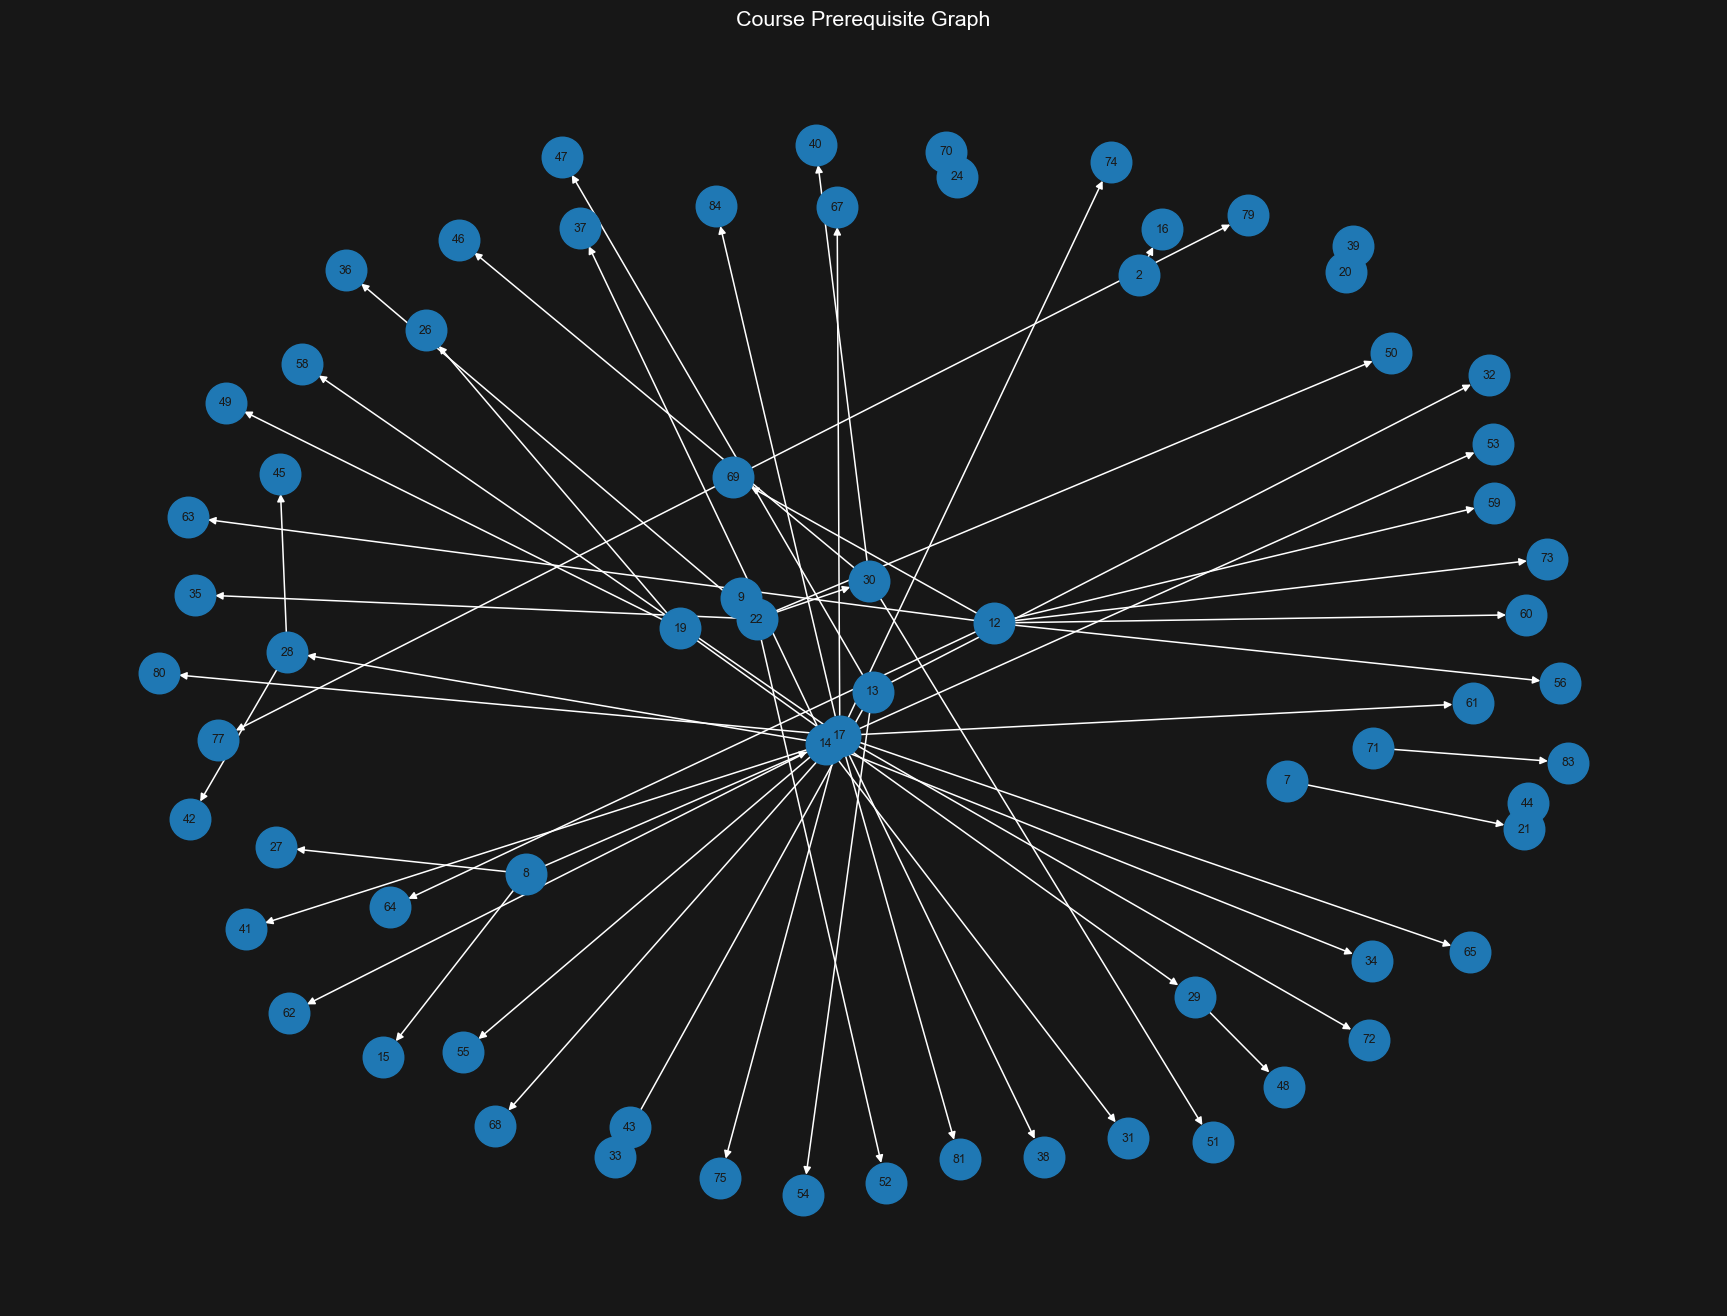

In [30]:
# Create the figure canvas and set its background color
fig = plt.figure(figsize=(20, 15), facecolor="#171717")  # Dark gray hex code

# Get the current axes and set its background color
ax = fig.add_subplot(111)
ax.set_facecolor("#090909")

pos = nx.spring_layout(G, seed=42)

# Draw the network
nx.draw_networkx(
    G,
    pos,
    ax=ax,  # Tell NetworkX to draw explicitly on our dark axes
    node_size=700,
    font_size=8,
    arrows=True,
    edge_color="white"
)

# Set the title with a light color so it's readable
plt.title("Course Prerequisite Graph", color="white", fontsize=14)
plt.axis("off")
plt.show()

#### Validate Curriculum

In [31]:
# Check for curriculum errors
# We need to check that there are no cycles
if nx.is_directed_acyclic_graph(G):
    print("The Gragh is Directed Acyclic (Contains no cycles)")
else:
    print("The Graph Include Cycles")
    list(nx.simple_cycles(G))

The Gragh is Directed Acyclic (Contains no cycles)


#### Graph Analysis

##### 1. Finding Descendants

In [32]:
# Finding descendants (unlock_count)
unlock_count = {
    course: len(nx.descendants(G, course)) 
    for course in G.nodes()
}

# Convert the unlock_count values to DataFrame 
unlock_df = pd.DataFrame({
    'course_id': list(unlock_count.keys()),
    'unlock_count': list(unlock_count.values())
})

# Merge with courses_df to get course names
unlock_df = unlock_df.merge(
    courses[['course_id', 'course_code', 'course_name']], 
    on='course_id', 
    how='left'
)

# Sort by most unlock count courses for easy viewing
unlock_df = unlock_df[['course_id', 'course_code', 'course_name', 'unlock_count']]
unlock_df = unlock_df.sort_values('unlock_count', ascending=False).reset_index(drop=True)

display(unlock_df.head(10).style.hide(axis="index"))

course_id,course_code,course_name,unlock_count
17,M231,Introduction to Statistics and Probability,13
8,M113,Calculus 2,12
9,M122,Mechanics 2,9
14,M214,Differential Equations 1,9
12,G102,Introduction to Computer Science,9
22,M223,Mechanics 4,8
13,M212,Abstract Algebra 1,5
19,M211,Real Analysis,4
30,M326,Analytical Mechanics,3
7,M112,Algebra and Geometry,2


##### 2. Finding Ancestors

In [33]:
# Ancestors answer: What must be completed before this course?
# This is useful later when checking if a student is eligible
# parameters are the graph "G" and the course_id
# # It returns ancestors as course_id list ordered from the Root
nx.ancestors(G, 48)


{19, 29}

In [34]:
# Returning a clean list of ancestor course names
def get_ancestors_list(G, course_id, courses_df):
    ancestors_ids = nx.ancestors(G, course_id)
    
    if not ancestors_ids:
        return ["No prerequisites"]
    
    result = courses_df[courses_df['course_id'].isin(ancestors_ids)][['course_code', 'course_name']]
    return result.values.tolist()

# Usage
ancestors = get_ancestors_list(G, 48, courses)
for code, name in ancestors:
    print(f"• {code} - {name}")

• M211 - Real Analysis
• M316 - Topology 1


##### 3. Count prerequisites

In [35]:
# Unlock Count: How many courses this course unlocks (descendants)
unlock_count = {
    course: len(nx.descendants(G, course)) 
    for course in G.nodes()
}

# Prerequisite Count: How many courses must be completed before this one (ancestors)
prerequisite_count = {
    course: len(nx.ancestors(G, course)) 
    for course in G.nodes()
}

# Instead of storing sets we store counts
unlock_df = pd.DataFrame({
    'course_id': list(unlock_count.keys()),
    'unlock_count': list(unlock_count.values()),
    'prerequisite_count': list(prerequisite_count.values())
})

# Merge with course details
G_df = unlock_df.merge(
    courses[['course_id', 'course_code', 'course_name']], 
    on='course_id', 
    how='left'
)

# Reorder columns
G_df = G_df[[
    'course_id', 
    'course_code', 
    'course_name', 
    'unlock_count',
    'prerequisite_count'
]]

# Sort by unlock_count (most impactful first)
G_df = G_df.sort_values('unlock_count', ascending=False).reset_index(drop=True)
display(G_df.head(10).style.hide(axis="index"))

course_id,course_code,course_name,unlock_count,prerequisite_count
17,M231,Introduction to Statistics and Probability,13,0
8,M113,Calculus 2,12,0
9,M122,Mechanics 2,9,0
14,M214,Differential Equations 1,9,1
12,G102,Introduction to Computer Science,9,0
22,M223,Mechanics 4,8,1
13,M212,Abstract Algebra 1,5,0
19,M211,Real Analysis,4,0
30,M326,Analytical Mechanics,3,2
7,M112,Algebra and Geometry,2,0


##### 4. Foundation courses

In [36]:
# Courses with In-degree = 0
# These are courses students can usually start with
foundation_courses = [
    node
    for node in G.nodes()
    if G.in_degree(node)==0
]
print("Foundation Courses ids are: ", foundation_courses)

Foundation Courses ids are:  [8, 2, 7, 19, 9, 13, 17, 20, 12, 24, 71]


##### 5. Terminal courses

In [37]:
# Courses with Out-degree = 0
# These are usually graduation-level courses
terminal_courses = [
    node
    for node in G.nodes()
    if G.out_degree(node)==0
]
print("Terminal Courses ids are: ", terminal_courses)

Terminal Courses ids are:  [15, 16, 26, 27, 31, 32, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 58, 59, 60, 61, 62, 63, 64, 65, 67, 68, 70, 72, 73, 74, 75, 77, 79, 80, 81, 83, 84]


##### 6. Topological ordering

In [38]:
# This gives a legal curriculum order
print(list(nx.topological_sort(G)))

[8, 2, 7, 19, 9, 13, 17, 20, 12, 24, 71, 14, 15, 27, 16, 21, 26, 29, 49, 22, 32, 33, 47, 54, 38, 58, 61, 62, 65, 67, 68, 72, 74, 75, 80, 81, 84, 39, 56, 59, 60, 63, 64, 69, 73, 70, 83, 28, 31, 34, 37, 41, 53, 55, 44, 48, 30, 35, 36, 50, 52, 43, 77, 79, 42, 45, 40, 46, 51]


##### 7. Longest prerequisite chain

In [39]:
print(nx.dag_longest_path(G))

[8, 14, 28, 42]


##### 8. Calculate graph depth

In [40]:
depth = {}

for course in G.nodes():

    depth[course] = len(
        nx.ancestors(G, course)
    )
print(depth)

{8: 0, 14: 1, 15: 1, 2: 0, 16: 1, 7: 0, 21: 1, 19: 0, 26: 1, 9: 0, 22: 1, 27: 1, 28: 2, 29: 1, 30: 2, 31: 2, 13: 0, 32: 1, 33: 1, 34: 2, 35: 2, 36: 2, 37: 2, 17: 0, 38: 1, 20: 0, 39: 1, 40: 3, 41: 2, 42: 3, 43: 2, 44: 2, 45: 3, 46: 3, 47: 1, 48: 2, 49: 1, 50: 2, 51: 3, 52: 2, 53: 2, 54: 1, 55: 2, 12: 0, 56: 1, 58: 1, 59: 1, 60: 1, 61: 1, 62: 1, 63: 1, 64: 1, 65: 1, 67: 1, 68: 1, 69: 1, 24: 0, 70: 1, 72: 1, 73: 1, 74: 1, 75: 1, 77: 2, 79: 2, 80: 1, 81: 1, 71: 0, 83: 1, 84: 1}


In [41]:
# Filter: Affecting GPA Courses
aff_gpa = courses[(courses['affects_gpa'] == True)]

# Getting the count of these courses
print(f"Total courses that are affecting GPA: **{len(aff_gpa)}**")

# Show the actual courses
print("\nList of these courses:")
display(aff_gpa[['course_id', 'course_code', 'course_name', 'course_program', 'course_level']])

Total courses that are affecting GPA: **82**

List of these courses:


,course_id,course_code,course_name,course_program,course_level
0,1,M111,Calculus 1,Mathematics,1
1,2,M121,Mechanics 1,Mathematics,1
2,3,P101,Properties of Heat and Matter,General,1
3,4,P102,"Electricity, Magnetism and Light",General,1
4,5,C102,General Chemistry 2,General,1
...,...,...,...,...,...
80,81,M435,Reliability Theory,Statistics,4
81,82,M444,Computer Graphics Systems,Computer Science,4
82,83,M445,Algorithm Design and Analysis,Computer Science,4
83,84,M436,Time Series and Forecasting,Statistics,4


- Some courses doesn't affect the gpa so the credit hours aren't considered
- But some of these courses are Required for Graduation
- Now calculating the Required Score "req_score"
- We need to know how many courses that are required but doesn't affect the cgpa


In [42]:
# Filter: Required but does NOT affect GPA
required_no_gpa = courses[(courses['type'] == 'Required') & 
                          (courses['affects_gpa'] == False)]

# Getting the count of these courses
print(f"Total courses that are Required but do NOT affect GPA: **{len(required_no_gpa)}**")

# Show the actual courses
print("\nList of these courses:")
display(required_no_gpa[['course_id', 'course_code', 'course_name', 'course_program', 'course_level']])

Total courses that are Required but do NOT affect GPA: **2**

List of these courses:


,course_id,course_code,course_name,course_program,course_level
5,6,G101,Human Rights and Anti-Corruption,General,1
17,18,G201,Scientific Terminology in English,General,2


- We note that thee are only 2 of 85 courses are required and not affecting the CGPA
- So they represent a tiny percentage of our course but has high importance


---

### Curriculum Leverage Score (CLS)

To quantify the academic importance of each course within the curriculum, a metric called the **Curriculum Leverage Score (CLS)** is produced. Which deosn't rely only on credit hours or prerequisite counts, CLS combines the **structural influence of a course within the prerequisite network** with its academic significance.

The score is defined as:

$$
\boxed{
CLS=
\left(
\frac{D+1}{P+1}
\right)_{norm}
\times
C_{norm}
\times
G
\times
R
}
$$

where:

| Symbol | Name | Description |
|--------|------|-------------|
| $D$ | Unlock Count (Cirruclum Reach) | Number of descendant courses unlocked after successfully completing the course. |
| $P$ | Prerequisite Count (Prerequisite Depth) | Number of ancestor courses that must be completed before taking the course. |
| $C_{norm}$ | Normalized Credit Hours | Credit hours normalized using Min-Max normalization. |
| $G$ | GPA Impact Factor | Academic contribution factor: **1.0** if the course affects GPA, otherwise **0.6**. |
| $R$ | Requirement Factor | Curriculum importance factor: **1.0** for required courses and **0.8** for elective courses. |

---

### Network Leverage

The structural importance of a course is first computed as

$$
NL=\frac{D+1}{P+1}
$$

where:

- Adding **1** to the numerator prevents terminal courses (courses with no descendants) from receiving a zero score.
- Adding **1** to the denominator prevents division by zero for foundation courses that have no prerequisites.

The resulting Network Leverage is then normalized using Min-Max normalization

---

### Final CLS Normalization

After computing CLS for all courses, the scores are normalized once more to produce values within the range **[0,1]**.
The normalized CLS is stored as the final importance score for each course and is later incorporated into the recommendation engine.

---

### Why This Metric?

The proposed CLS integrates four complementary aspects of curriculum importance:

- **Curriculum Influence** — Courses that unlock many future courses receive higher importance.
- **Curriculum Difficulty** — Courses requiring many prerequisites have their leverage moderated.
- **Academic Workload** — Courses with higher credit hours contribute more to the score.
- **Academic Priority** — Courses affecting GPA and required for graduation receive additional importance.

CLS models the interaction between these factors, providing a comprehensive representation of a course's academic significance within the curriculum.

---

### Advantages

- ✔ Incorporates prerequisite network structure.
- ✔ Reflects the long-term curriculum impact of each course.
- ✔ Rewards academically significant and mandatory courses.
- ✔ Produces normalized scores suitable for recommendation algorithms.
- ✔ Fully explainable and interpretable, making it appropriate for educational recommendation systems.

In [43]:
# Calculate components of our formula
# Calculating the Network Laverage NL
G_df['NL'] = (G_df['unlock_count'] + 1) / (G_df['prerequisite_count'] + 1)

# Now normalizing the NL using our predefined min_max_normalize function
G_df["NL"] = min_max_normalize(G_df["NL"])

# Calculating the Academic Load Impact = normalized credit hours * GPA Impact
G_df['C*G'] = courses['credit_score'] * np.where(courses['affects_gpa'], 1.0, 0.6)

# Calculating Requirement Factor
G_df['R'] = np.where(courses.loc[G_df.index, 'type'] == 'Required', 1.0, 0.8)

# Now Printing the G_df table with calculated metrics
display(G_df.head(10).style.hide(axis="index"))

course_id,course_code,course_name,unlock_count,prerequisite_count,NL,C*G,R
17,M231,Introduction to Statistics and Probability,13,0,1.000000,1.000000,1.000000
8,M113,Calculus 2,12,0,0.927273,1.000000,1.000000
9,M122,Mechanics 2,9,0,0.709091,1.000000,1.000000
14,M214,Differential Equations 1,9,1,0.345455,1.000000,1.000000
12,G102,Introduction to Computer Science,9,0,0.709091,1.000000,1.000000
22,M223,Mechanics 4,8,1,0.309091,0.000000,1.000000
13,M212,Abstract Algebra 1,5,0,0.418182,1.000000,1.000000
19,M211,Real Analysis,4,0,0.345455,1.000000,1.000000
30,M326,Analytical Mechanics,3,2,0.078788,1.000000,1.000000
7,M112,Algebra and Geometry,2,0,0.200000,1.000000,1.000000


### Now, calculating the final Cirruclum Laverage Score (CLS):

$$
\boxed{
CLS=
\left(
\frac{D+1}{P+1}
\right)_{norm}
\times
C_{norm}
\times
G
\times
R
}
$$

In [44]:
# Calculating the importance formula value
G_df["CLS"] = G_df["NL"] * G_df["C*G"] * G_df["R"]

# Now Printing the G_df table with calculated metrics
display(G_df.head(10).style.hide(axis="index"))

course_id,course_code,course_name,unlock_count,prerequisite_count,NL,C*G,R,CLS
17,M231,Introduction to Statistics and Probability,13,0,1.000000,1.000000,1.000000,1.000000
8,M113,Calculus 2,12,0,0.927273,1.000000,1.000000,0.927273
9,M122,Mechanics 2,9,0,0.709091,1.000000,1.000000,0.709091
14,M214,Differential Equations 1,9,1,0.345455,1.000000,1.000000,0.345455
12,G102,Introduction to Computer Science,9,0,0.709091,1.000000,1.000000,0.709091
22,M223,Mechanics 4,8,1,0.309091,0.000000,1.000000,0.000000
13,M212,Abstract Algebra 1,5,0,0.418182,1.000000,1.000000,0.418182
19,M211,Real Analysis,4,0,0.345455,1.000000,1.000000,0.345455
30,M326,Analytical Mechanics,3,2,0.078788,1.000000,1.000000,0.078788
7,M112,Algebra and Geometry,2,0,0.200000,1.000000,1.000000,0.200000


In [45]:
G_df.describe()

,course_id,unlock_count,prerequisite_count,NL,C*G,R,CLS
count,69.000000,69.000000,69.000000,69.000000,69.000000,69.000000,69.000000
mean,45.000000,1.231884,1.231884,0.094159,0.507246,0.962319,0.082477
std,22.165819,2.931296,0.807045,0.206669,0.503610,0.078780,0.207896
min,2.000000,0.000000,0.000000,0.000000,0.000000,0.800000,0.000000
25%,28.000000,0.000000,1.000000,0.006061,0.000000,1.000000,0.000000
50%,45.000000,0.000000,1.000000,0.018182,1.000000,1.000000,0.000000
75%,63.000000,1.000000,2.000000,0.054545,1.000000,1.000000,0.018182
max,84.000000,13.000000,3.000000,1.000000,1.000000,1.000000,1.000000


- the CLS.min()=0, and CLS.max()=1
- so, values are already ranged between 0 & 1
- so, no need to normalize once more

---
---


## **`Part II: Board Rules Logic`**

---
---

#### 1. **Board Rules Overview**
#### 2. **Helper Functions (R1, R2, ...)**
#### 3. **Main Validation Function**
#### 4. **Interactive Enrollment System**

---

### Board Rules & Edge Case Handling

- This part translates **every university board rule** into executable Python functions.
---

### Comprehensive Enforcement of All Board Rules:

A summary of all key rules extracted from the BoardRules.pdf (Mansoura University Faculty of Science - Bachelor’s Internal Regulations), organized by مادة (Article):


- (Article 1): Objectives of the Faculty
- (Article 2): Academic Departments & Programs:
    - 6 scientific departments.
    - 25 academic programs.
- (Aeticle 4): Awarded Degree:
    - Bachelor of Science (B.Sc.) in one of the listed specializations.
- (Article 5): Study System:
    - Credit Hours System within one semester framework.
- (Article 6): Duration of Study:
    - 4 academic years = 8 semesters (4 levels).
    - Each level consists of 2 semesters.
    - Student cannot graduate unless all graduation requirements are met, even if study period exceeds 4 years.
- (Article 7): Regular Semester Structure:
    - Registration period: 1 week
    - Study period: 14 weeks
    - Final Exam period: 2 weeks
- (Article 8): Summer Semester:
    - Intensive summer semester (6 weeks).
    - Only for failed courses.
    - Maximum 8 credit hours.
- (Article 9): Credit Hour Definition:
    - Theoretical lecture: 1 credit hour = 1 hour/week.
    - Practical/Lab: 1 credit hour = 2–3 hours/week.
- (Article 10): Graduation Requirements:
    - Minimum 146 credit hours.
    - University Requirements: 8 hours (Computer, English, Human Rights, Cultural Studies).
    - Some University Requirements (e.g., Human Rights) do not affect GPA.
    - College Requirements: 30 hours (mostly Level 1).
    - Specialization Requirements: 108 hours.
- (Article 11): Academic Registration & Load:
    - Normal load: 28-36 credit hours per level (across two semesters).
    - Level 1: 28-28 credits (across two semesters).
    - Outstanding students (CGPA ≥ 3.0): Can take extra 2–3 credits/semester (max +8 total).
    - CGPA ≤ 1.0: Maximum 14 credit hours per semester.
    - Final semester: Council may allow +4 credits to graduate.
- (Article 12): Add/Drop/Withdrawal:
    - Add/Drop: Until end of week 4.
    - Withdrawal: Until end of week 6 (recorded as "Withdrawn").
    - Changing specialization: Allowed with approval.
- (Article 13): Attendance Rules:
    - Maximum absence: 25% of total course hours.
    - IF > 25% without excuse → 2 Warning → (Banned) → Automatic Fail.
- (Article 14): Assessment & Grading System:
    | التقدير (Arabic)     | Symbol | Points          | Percentage Range          | English Equivalent     |
    |-----------------------|--------|-----------------|---------------------------|------------------------|
    | ممتاز                | أ      | 3.5 - 5.0      | 85% - 100%               | Excellent             |
    | جيد جداً             | ب      | 2.5 - <3.5     | 75% - <85%               | Very Good             |
    | جيد                  | ج      | 1.5 - <2.5     | 65% - <75%               | Good                  |
    | مقبول                | د      | 1.0 - <1.5     | 60% - <65%               | Acceptable / Pass     |
    | راسب                 | ر      | 0              | <60%                     | Fail                  |
    | غائب                 | غ      | 0              | -                        | Absent                |
    | غير مكتمل            | غ م    | 0              | -                        | Incomplete            |
    | منسحب                | من     | 0              | -                        | Withdrawn             |
    | محروم                | مح     | 0              | -                        | Banned from Exam      |
    - Minimum passing grade: 60%.
    - Honors: Cumulative GPA ≥ 2.5 with no failures.
    - Graduation: Cumulative GPA ≥ 1.0.

- (Article 15): GPA Calculation:
    - Semester GPA = (Sum of (points × credits)) / Total credits.
    - Cumulative GPA uses all semesters.
    - Only latest grade counts when repeating a course.
- (Article 16): Academic Warning & Dismissal:
    - First warning: Semester GPA < 1.0.
    - Second warning: Two consecutive semesters < 1.0 → Restricted to 14 credits.
    - Third warning → Possible dismissal.


---
A **master validator** (`validate_enrollment`) runs all applicable rules for a given student × course combination and returns a single consolidated report.

---
#### Phase 1 — Student Validation

Before generating any recommendation, the following student information must be available:

- Student ID
- Current Semester

If any mandatory information is missing, the recommendation process must stop until the required data is completed.

In [46]:
# Get input from user (Student ID and Semester) and check if student in the database
def get_student_input():
    print("Bloom Academic - Course Enrollment System\n")
    
    # For Student ID checking
    while True:
        try:
            student_id = int(input("\nEnter MU Student ID: ").strip())
            
            if student_id <= 0:
                print("❌ Student ID must be positive.")
                continue
            
            # Check if student exists
            student_row = students[students['student_id'] == student_id]
            
            if student_row.empty:
                print(f"❌ Student ID {student_id} not found. Please try again.")
                continue
            
            # Student found
            student = student_row.iloc[0]
            print(f"✅ Student found: {student['student_name']} (Level {student['student_level']}, CGPA: {student['CGPA']})")
            break
            
        except ValueError:
            print("❌ Please enter a valid numeric Student ID.")
    
    # For semester input cases checking
    while True:
        semester_input = input("Enter Semester Number or 's' for Summer: ").strip().lower()
        
        if semester_input == 'S':
            break
        
        try:
            sem_num = int(semester_input)
            if 1 <= sem_num:
                break
            else:
                print("❌ Semester number must be 1 as minimum")
        except ValueError:
            print("❌ Invalid input. Please enter a number or 's' for Summer.")
    
    print(f"\nProcessing for Student ID: {student_id} | Semester: {semester_input}\n")
    
    return student_id, semester_input

`FrontEnd: Show Loading icon`



#### Enrollment Rules:

| Rule | Category | Source | Formula / Condition |
|------|----------|------|---------------------|
| R1 | Semester Parity | Article 5 & 6 | if number or summer |
| R2 | Level Progression | Article 16 | `credits_passed >= threshold[level]` |
| R3 | Prerequisites | Official Curriculum | all prereq courses passed |
| R4 | Credit Minimum | Article 11 & 16 | `planned_hours >= 14` |
| R5 | CGPA Credit Limit | Article 11 | `planned_hours <= max_credit_hours` |
| R6 | Bonus Course Repetition | Article 15 | can't repeat already-passed course unless opening extra level |
| R7 | Summer Rules | Article 8 | only failed courses, max 8 hrs |
| R8 | Even-Odd Semester | Article 5, 6 | `student_parity == course_parity` |
| R9 | Outstanding Bonus | Article 11 | CGPA ≥ 3.0 → +2 credit bonus |
| R10 | Warning Status | Article 16 | probation → exactly 14 hrs, required only |
| R11 | Graduation Eligibility | Article 10 & 14 | CGPA ≥ 1.0, ≥ 146 credits, all required done |
| R12 | Absence Limit | Article 13 | absence > 25% → 2 warnings then banned from exam |


---
### **Rule R1: Semester Parity Check:**


| Current Semester | Available Courses |
|------------------|------------------|
| Odd Semester | Odd-semester courses only |
| Even Semester | Even-semester courses only |
| Summer Semester | Previously failed courses only |
| Bonus | Previously attempted courses (passed or failed) only|


---

### **Rule R6: Bonus Course Repeation**
- Students whose CGPA is not exceeding the minimum to graduate the open a new bonus level
- Bonus semesters allows only to enroll in failed/passsed courses 
- Semester Parity to be even or odd is considered

In [47]:
def semester_b(courses: pd.DataFrame, student_history: pd.DataFrame, student_semester: int) -> pd.DataFrame:
    # Checking and returning matched courses parity
    student_parity = int(student_semester) % 2
    courses = courses[courses['semester_number'] % 2 == student_parity]

    # Make only failed/passed status available
    # Check if student_score < 65
    attempted = student_history.loc[student_history["student_score"] < 65, "course_id"]
    return courses[courses["course_id"].isin(attempted)]

---

### **Rule R7: Summer Rules**
- student can enroll only in failed status courses
- student can enroll only in 8 hours maximum

In [48]:
def semester_s(courses: pd.DataFrame, student_history: pd.DataFrame, students: pd.DataFrame, student_id: int) -> pd.DataFrame:    
    # Set only this student's maximum credit hours
    students.loc[students["student_id"] == student_id, "max_credit_hours"] = 8

    # Determining only failed courses to set available
    failed = student_history.loc[student_history["student_score"] < 60, "course_id"]

    return courses[courses["course_id"].isin(failed)]


---

### **Rule R8: Even-Odd Semester**
- A student currently in an **odd** semester (1, 3, 5, 7) may only register courses whose `semester_parity = 'o'`.  
- A student in an **even** semester (2, 4, 6, 8) may only register courses with `semester_parity = 'e'`.

In [49]:
def semester_eo(courses: pd.DataFrame, history: pd.DataFrame, student_semester: int) -> pd.DataFrame:
    # Checking and returning matched courses parity
    student_parity = int(student_semester) % 2
    courses = courses[courses['semester_number'] % 2 == student_parity]

    # Returning all possible courses except passed
    passed = history[history['student_score'] >= 60]['course_id'].tolist()
    return courses[~courses['course_id'].isin(passed)]

---



### **Rule R2: Level Progression Check**

 - Takes pre-calculated level as input
  - Checks if student has enough credits for that level

- We Need to use the number of total passed credit hours for each student
- We will do it using "lambda" function as Anonymous function that takes one student ID (`sid`) at a time.


In [50]:
students['total_credits'] = students['student_id'].apply(
    lambda sid: history[(history['student_id'] == sid) & 
                        (history['student_score'] >= 60)]          # Filter only passed courses
                .merge(courses[['course_id', 'credit_hours']], 
                       on='course_id', 
                       how='left')['credit_hours']
                .sum()                                             # Sum credits of passed courses
)

students.head().style.hide(axis="index")

student_id,student_name,student_level,student_program,CGPA,total_failed_subjects,total_credits
1,Abdelrahman Ahmed,4,Statistics and Computer Science,3.900000,0,100
2,Hossam Hamdy,2,Mathematics,2.400000,2,60
3,Salma Elmongy,2,Statistics and Computer Science,3.100000,0,38
4,Farouk Ahmed,3,Statistics and Computer Science,1.700000,5,50
5,Hend Magdy,4,Mathematics,1.100000,9,38


---

### **Rule R5: CGPA Credit Limit**

#### Maximum Credit Hours to Enroll:
Board Rule 3.2 + 2 (Credit Hours):

- CGPA ≤ 1.0           → exactly 14 credit hours (FIXED — no flexibility)
- 1.0 < CGPA < 3.0     → up to 18 credit hours
- CGPA ≥ 3.0           → up to 20 credit hours (outstanding student +2 bonus)


In [51]:
def max_credit_hours(cgpa):
    if cgpa <= 1.0:  return 14
    elif cgpa < 3.0: return 18
    else:            return 20

# Applying Maximum Credit Hours Function and add as a new column to the students table
students["max_credit_hours"] = students["CGPA"].apply(max_credit_hours)

# Displaying the Student table with the new added column
students.head(10).style.hide(axis="index")

student_id,student_name,student_level,student_program,CGPA,total_failed_subjects,total_credits,max_credit_hours
1,Abdelrahman Ahmed,4,Statistics and Computer Science,3.900000,0,100,20
2,Hossam Hamdy,2,Mathematics,2.400000,2,60,18
3,Salma Elmongy,2,Statistics and Computer Science,3.100000,0,38,20
4,Farouk Ahmed,3,Statistics and Computer Science,1.700000,5,50,18
5,Hend Magdy,4,Mathematics,1.100000,9,38,18
6,Maher Mohamed,1,Mathematics,3.500000,0,32,20
7,Abdelrahmen Kewan,4,Statistics and Computer Science,2.000000,3,65,18
8,Mohamed Mostafa,4,Statistics and Computer Science,4.000000,0,100,20
9,Laila Ismail,3,Statistics and Computer Science,4.500000,0,71,20
10,Ali Ibrahim,2,Mathematics,0.500000,10,0,14


---

### **Rule R9: Outstanding Bonus**
- If student's CGPA >= 3.0 so they can add up to 2 credits
- already applied in rule R5

---

### **Rule R10: Academic Warning Status**
Board Rule 2.3 warning system:

- CGPA < 1.0  → Probation (2nd warning) — locked to 14 credits, required only
- CGPA < 2.0  → Warning (1st warning)   — advisory level
- CGPA ≥ 2.0  → Good Standing

In [52]:
def warning_status(cgpa):
    if cgpa < 1.0:   return "Probation"
    elif cgpa < 2.0: return "Warning"
    else:            return "Good Standing"

# Applying Student Academic Warning Status Function and add as a new column to the students table
students["warning_status"] = students["CGPA"].apply(warning_status)

# Applying Probation case to take only 14 credits
students.loc[students["warning_status"] == "Probation", "max_credit_hours"] = 14

# Displaying the Student table with the new added column
students.head(10).style.hide(axis="index")

student_id,student_name,student_level,student_program,CGPA,total_failed_subjects,total_credits,max_credit_hours,warning_status
1,Abdelrahman Ahmed,4,Statistics and Computer Science,3.900000,0,100,20,Good Standing
2,Hossam Hamdy,2,Mathematics,2.400000,2,60,18,Good Standing
3,Salma Elmongy,2,Statistics and Computer Science,3.100000,0,38,20,Good Standing
4,Farouk Ahmed,3,Statistics and Computer Science,1.700000,5,50,18,Warning
5,Hend Magdy,4,Mathematics,1.100000,9,38,18,Warning
6,Maher Mohamed,1,Mathematics,3.500000,0,32,20,Good Standing
7,Abdelrahmen Kewan,4,Statistics and Computer Science,2.000000,3,65,18,Good Standing
8,Mohamed Mostafa,4,Statistics and Computer Science,4.000000,0,100,20,Good Standing
9,Laila Ismail,3,Statistics and Computer Science,4.500000,0,71,20,Good Standing
10,Ali Ibrahim,2,Mathematics,0.500000,10,0,14,Probation


---

### **Rule R4: Credit Minimum**
- Planned credits must be >= 14
- Except for summer course it's 8 as maximum

In [53]:
students.describe()

,student_id,student_level,CGPA,total_failed_subjects,total_credits,max_credit_hours
count,500.000000,500.000000,500.00000,500.000000,500.000000,500.000000
mean,250.500000,2.368000,2.22548,1.240000,49.804000,18.100000
std,144.481833,1.109522,0.85775,2.155851,35.672267,1.437405
min,1.000000,1.000000,0.10000,0.000000,0.000000,14.000000
25%,125.750000,1.000000,1.61500,0.000000,19.000000,18.000000
50%,250.500000,2.000000,2.15500,0.000000,38.000000,18.000000
75%,375.250000,3.000000,2.85000,1.000000,71.000000,18.000000
max,500.000000,4.000000,4.84000,13.000000,134.000000,20.000000


---

### **Rule R3: Prerequisites passing check**
- Checks if the student has passed all required prerequisites for each course (R3). Returns eligible and ineligible courses.

In [54]:
def check_prerequisites(available_courses: pd.DataFrame, 
                       student_id: int, 
                       history_df: pd.DataFrame, 
                       courses_df: pd.DataFrame, 
                       prerequisites: pd.DataFrame = None, 
                       verbose: bool = True) -> dict:
    passed = history_df[(history_df['student_id'] == student_id) & 
                        (history_df['student_score'] >= 60)]['course_id'].tolist()
    
    eligible = []
    ineligible = []
    
    for _, course in available_courses.iterrows():
        cid = course['course_id']
        required = prerequisites[prerequisites['course_id'] == cid]['required_course_id'].tolist() if prerequisites is not None else []
        
        missing = [r for r in required if r not in passed]
        
        if not missing:
            eligible.append(course)
        else:
            ineligible.append({
                'course_id': cid,
                'course_name': course['course_name'],
                'missing_count': len(missing)
            })
    
    eligible_df = pd.DataFrame(eligible) if eligible else pd.DataFrame(columns=available_courses.columns)
    
    if verbose:
        print(f"Prerequisites Check: {len(eligible)} eligible, {len(ineligible)} blocked")
    
    return {
        'eligible': eligible_df,
        'ineligible': ineligible
    }

---

#### **Performing All Board Rules using one function collects and runs all predefined functions**

In [55]:
def validate_enrollment():

    # Get input from user, validate them, and store returned values in variables
    student_id, semester_input = get_student_input()

    # Calculate level from semester_input
    if str(semester_input).upper() == 'S':
        calculated_level = 0  # Special value for Summer
    else:
        try:
            sem = int(semester_input)
            if sem % 2 == 0:   # Even semester
                calculated_level = sem // 2
            else:              # Odd semester
                calculated_level = (sem + 1) // 2
        except:
            calculated_level = 1  # fallback

    # Get student's history
    student_history = history[history['student_id'] == student_id]

    # Starts with a full copy of the courses table
    available = courses.copy()
    

    # Apply Semester Rules
    if semester_input <= 8:
        available = semester_eo(available, student_history, semester_input)
    elif str(semester_input).lower() == 's':
        available = semester_s(available, student_history, students, student_id)
    else:
        available = semester_b(available, student_history, semester_input)


    # Applying Prerequisite Check Function
    prereq_result = check_prerequisites(
        available_courses=available,
        student_id=student_id,
        history_df=history,
        courses_df=courses,
        prerequisites=prerequisites,
        verbose=True
    )
    available = prereq_result['eligible']

    return available

##### **Applying CLs to order available courses descending with respect to their importance weights using graph theory**


Since we already built the prerequisite graph `G` and calculated the **Curriculum Leverage Score (CLS)** in `G_df` during Part I, we now merge the filtered `available` courses with `G_df` to retrieve the pre-computed importance scores.
 - we get CLS for available courses
 - then sort courses descendingly due to importance weight
 - after that we show only a specific number of available courses to enroll that satisifies the max allowed credit limit for the student

In [56]:
# Reviewing G_df table to know included columns
G_df.head(1).style.hide(axis="index")

course_id,course_code,course_name,unlock_count,prerequisite_count,NL,C*G,R,CLS
17,M231,Introduction to Statistics and Probability,13,0,1.000000,1.000000,1.000000,1.000000


In [ ]:
# Get filtered courses (rules applied) from the main function
# Get student data
student_id, semester_input = get_student_input()

student_row = students[students['student_id'] == student_id]
student = student_row.iloc[0]

available = validate_enrollment()

# Merge filtered available courses with pre-computed G_df (CLS table)
available_cls = available.merge(
    G_df[['course_id', 'unlock_count', 'prerequisite_count', 'NL', 'CLS']], 
    on='course_id', 
    how='left')

# Sort by CLS (most important first)
available_cls = available_cls.sort_values(by='CLS', ascending=False).reset_index(drop=True)

# Get student's max allowed credits
max_credits = student.get('max_credit_hours', 18)   # fallback 18

# Greedy selection: Add highest CLS courses until max credits reached
selected = []
current_sum = 0

for _, course in available_cls.iterrows():
    if current_sum + course['credit_hours'] <= max_credits:
        selected.append(course)
        current_sum += course['credit_hours']
    else:
        break  # Stop when adding next course would exceed limit

selected_c = pd.DataFrame(selected)

print(f"\n Recommended Courses (Max {max_credits} credits):")
print(f"Total Selected Credits: {current_sum} / {max_credits}")

display_cols = ['course_id', 'course_code', 'course_name', 'credit_hours', 'type', 'CLS']
display(selected_c[display_cols].style.format({'CLS': '{:.4f}'}))

After showing the ranked available courses:
- We show the list of recommended courses as clickable options (buttons).
- When the student clicks on a course → Open the BloomReady Module for that course.

---
---


## **`Part III: BloomReady Module`**

---
---

#### **In this part we need to perform the following:**
- Allow syllabus upload and read them using python.
- Analyze syllabus content with Gemini Flash.
- Show required prerequisite notes.
- Offer the Bloom’s Taxonomy MCQ self-test.
- Show readiness percentage and score.

---

#### **Allow Syllabus Upload & Text Extraction**:
- when the personalized list of courses appear
- Student clicks on any of theses courses names as a button
- After clicking a box appear to upload course syllabus

In [ ]:
# Handling syllabus upload from user and get file path
# Supports: PDF, DOCX, PPTX
uploaded_file = st.file_uploader("Upload Course Syllabus", type= ["pdf", "docx", "pptx"], help= "Supported Formats: PDF, DOCX, PPTX")
if uploaded_file:
    path = Path(uploaded_file.name).suffix.lower()
    st.write("File Name: ", uploaded_file.name)
    st.write("Extension: ", path)
    st.write("Size: ", uploaded_file.size, "Bytes")

#### For the uploaded file, the code supports only 3 path extensions (pdf, docx, pptx)
so we need to use python ibraries to extract text from these pathes

In [ ]:
# Extracting text from pdf using pdfplumber
def extract_pdf(pdf_file):
    text = ""

    with pdfplumber.open(pdf_file) as pdf:
        for page in pdf.pages:
            page_text = page.extract_text()
            if page_text:
                text += page_text + "\n"

    return text

In [ ]:
# Extracting text from PowerPoint using presentation
def extract_pptx(pptx_file):
    presentation = Presentation(pptx_file)
    text = ""
    for slide in presentation.slides:
        for shape in slide.shapes:
            if hasattr(shape, "text"):
                text += shape.text + "\n"
    return text

In [63]:
# Extracting text from Word Document using docx
def extract_docx(doc_file):
    doc = docx.Document(doc_file)
    text = "\n".join(
        paragraph.text
        for paragraph in doc.paragraphs)
    return text

#### After setting all path types extraction we now use the main extracting function

In [ ]:
# Reading uploaded files by text extracting main function
def extract_text(uploaded_file):
    path = Path(uploaded_file.name).suffix.lower()
    if path == ".pdf":
        return extract_pdf(uploaded_file)
    if path == ".docx":
        return extract_docx(uploaded_file)
    if path == ".pptx":
        return extract_pptx(uploaded_file)
    
text = extract_text(uploaded_file)

**After extracting text from the file we need to clean it before analyzing:**
- The integrated LLM can handel this task but I prefered to do it previously for more consistent AI responses.
- It helps the model not to be confused and provide cleaner outputs with less halusination probability 
- By using `re` Library we can fix many issues that the pdf may contain, ex:
    - Multiple blank lines/Broken line breaks
    - Extra spaces/tabs
    - Page numbers/Headers/footers repeated on every page


In [ ]:
def clean_text(text):
    # Replace multiple spaces/tabs with one space
    text = re.sub(r"[ \t]+", " ", text)

    # Replace 3+ consecutive newlines with two
    text = re.sub(r"\n{3,}", "\n\n", text)

    # Remove page numbers like "Page 3"
    text = re.sub(r"Page\s+\d+", "", text, flags=re.IGNORECASE)

    return text.strip()

syllabus_text = clean_text(text)

---

#### Analyze syllabus content with Gemini Flash:
- we now need to send the file content "course_text" to the LLM to analyze it
- then the LLM can understand required prerequisite to make: 
    - Notes to return as PDF
    - JSON MCQ to return as Self-Assessement

#### When user uploads the syllabus file, they are asked if they want which of these 2 options:
- Get Syllabus Notes: content brief, covered skills, prerequisites needed to take this course,... all in pdf file format
- Take Assessment: using Bloom's Taxonomy the system builds MCQ self-assessment and grade to give readiness score

### **1. Analyze Syllabus to get PDF Notes:**
- Detailing a promt for the LLM with syllabus_text
- Analyze syllabus_text content and extract full detailed notes
- Get parts from returned JSON texts to build PDF
- Use FPDF Python library to customize the pdf 
- Enable the Generated PDF to be downloaded by user

In [ ]:
# Deep analysis of any syllabus or learning content.
# Returns structured notes suitable for PDF generation.
def analyze_notes(syllabus_text: str) -> dict:
    prompt = f"""
You are an expert academic advisor, curriculum analyst, and instructional designer with 15+ years of experience in higher education and professional certification programs. 
Your task is to perform a rigorous pedagogical analysis of the provided academic content.

## **INPUT CONTENT TO ANALYZE**
<syllabus>
{syllabus_text}
</syllabus>

## **CRITICAL INSTRUCTIONS**
1. **Validate the input first.** If the content is not a syllabus, curriculum outline, or learning material, return a JSON with `"error": 
"Input does not appear to be academic content. Please provide a syllabus or curriculum document."` and cease all other output.
2. **Think step-by-step** before generating the final JSON. Internally analyze:
   - What is the subject domain and academic level (undergraduate, graduate, professional)?
   - What is the implied learning trajectory?
   - Which skills are explicitly stated vs. implicitly required?
   - What foundational knowledge must a learner possess to avoid cognitive overload?
3. **Be conservative with prerequisites.** Only list skills/topics that are genuinely necessary to understand the material, not tangentially related subjects.
4. **Ensure educational depth.** `detailed_notes` must contain substantive explanations a struggling student could actually learn from, not just restatements of titles.
5. **Return ONLY valid, minified JSON.** No markdown code blocks, no commentary, no explanations outside the JSON structure.

## **OUTPUT SCHEMA**
Return a single JSON object adhering exactly to this structure:

{{
  "metadata": {{
    "subject_domain": "Primary academic discipline (e.g., 'Computer Science', 'Biomedical Engineering')",
    "estimated_academic_level": "Undergraduate introductory / Undergraduate advanced / Graduate / Professional certification",
    "content_type": "Syllabus / Course outline / Learning module / Certification prep guide",
    "analysis_confidence": "High / Medium / Low -- based on clarity and completeness of input"
  }},
  "brief_summary": "A precise 2-3 sentence overview capturing the scope, level, and primary objective of the content.",
  "main_topics": [
    "Topic 1: include a brief descriptor (e.g., 'Linear Algebra: matrices, vector spaces, and eigenvalues')",
    "Topic 2...",
    "..."
  ],
  "covered_skills": [
    "Observable, measurable skill (e.g., 'Implement gradient descent in Python')",
    "..."
  ],
  "prerequisites": {{
    "required_skills": [
      "Skill absolutely necessary to begin (e.g., 'Proficiency in Python syntax and data structures')"
    ],
    "required_topics": [
      "Topic absolutely necessary to begin (e.g., 'Single-variable calculus through integration')"
    ],
    "recommended_skills": [
      "Helpful but not mandatory skills (e.g., 'Familiarity with Git version control')"
    ],
    "recommended_topics": [
      "Helpful but not mandatory background (e.g., 'Basic statistics')"
    ]
  }},
  "detailed_notes": {{
    "Prerequisite Topic Title": "A thorough, multi-sentence explanation of why this topic matters for the syllabus, what specific sub-concepts are most relevant, 
    and how gaps in this area will manifest as difficulties in the course. Include concrete examples where possible.",
    "..."
  }},
  "learning_trajectory": {{
    "phase_1": "Description of what the learner masters in the first third",
    "phase_2": "Description of the middle progression",
    "phase_3": "Description of the culminating skills/knowledge"
  }},
  "recommendations": {{
    "preparation_strategy": "Specific, actionable steps to bridge prerequisite gaps before Day 1",
    "study_approach": "Evidence-based study methodology suited to this material (e.g., spaced repetition for vocabulary-heavy subjects; project-based learning for coding)",
    "resources_suggestion": "Types of resources to seek (e.g., 'Interactive platforms like LeetCode for algorithms practice')",
    "time_estimate": "Estimated hours of pre-work recommended for a student with the required prerequisites",
    "risk_factors": "Common reasons students struggle with this material and how to mitigate them"
  }}

## **SELF-CORRECTION PASS**
1- Immediately after generating the JSON above, review your own output against these criteria:
2- Are any prerequisites actually *taught within* the syllabus itself? If yes, move them to `main_topics` and remove from prerequisites.
3- Does every item in `detailed_notes` contain at least one concrete example or manifestation of knowledge gaps?
4- Is the `estimated_academic_level` consistent with the complexity of vocabulary and concepts identified?
5- Output ONLY the corrected final JSON. Do not include your self-correction commentary.
}}
"""
    
    try:
        response = llm(prompt)  # Our existing llm() function
        
        # Clean response
        cleaned = response.strip()
        if "```json" in cleaned:
            cleaned = cleaned.split("```json")[1].split("```")[0]
        elif "```" in cleaned:
            cleaned = cleaned.split("```")[1]
        
        analysis = json.loads(cleaned.strip())
        
        print("✅ Deep syllabus analysis completed successfully.")
        return analysis
        
    except Exception as e:
        print(f"❌ Error during analysis: {e}")
        # Fallback response
        return {
            "brief_summary": "Unable to analyze the provided content.",
            "main_topics": ["Review the material manually"],
            "covered_skills": ["Critical thinking", "Subject-specific skills"],
            "prerequisites": {
                "required_skills": ["Basic knowledge in the field"],
                "required_topics": ["Foundational concepts"],
                "recommended_skills": [],
                "recommended_topics": []
            },
            "detailed_notes": {
                "Note": "Analysis failed. Please try uploading a clearer document."
            },
            "learning_trajectory": {},
            "recommendations": {
                "preparation_strategy": "Review basic concepts before proceeding."
            }
        }

### **Generates a professional PDF from the analysis output:**

In [ ]:
def pdf_notes(analysis: dict) -> bytes:
    pdf = FPDF()
    pdf.add_page()
    pdf.set_auto_page_break(auto=True, margin=10)
    
    # Header
    pdf.set_font("Arial", 'B', 16)
    pdf.cell(0, 12, "Study Notes & Preparation Guide", ln=True, align='C')
    pdf.set_font("Arial", size=10)
    pdf.cell(0, 8, f"Generated on: {datetime.datetime.now().strftime('%Y-%m-%d %H:%M')}", ln=True, align='C')
    pdf.ln(15)
    
    # Brief Summary
    pdf.set_font("Arial", 'B', 13)
    pdf.cell(0, 10, "Brief Summary", ln=True)
    pdf.set_font("Arial", size=11)
    pdf.multi_cell(0, 8, analysis.get("brief_summary", "No summary available."))
    pdf.ln(10)
    
    # Main Topics
    pdf.set_font("Arial", 'B', 13)
    pdf.cell(0, 10, "Main Topics Covered", ln=True)
    pdf.set_font("Arial", size=11)
    for topic in analysis.get("main_topics", []):
        pdf.cell(0, 8, f"• {topic}", ln=True)
    pdf.ln(10)
    
    # Covered Skills
    pdf.set_font("Arial", 'B', 13)
    pdf.cell(0, 10, "Covered Skills", ln=True)
    pdf.set_font("Arial", size=11)
    for skill in analysis.get("covered_skills", []):
        pdf.cell(0, 8, f"• {skill}", ln=True)
    pdf.ln(10)
    
    # Prerequisites
    pdf.set_font("Arial", 'B', 13)
    pdf.cell(0, 10, "Prerequisite Topics & Skills", ln=True)
    pdf.set_font("Arial", size=11)
    prereqs = analysis.get("prerequisites", {})

    pdf.cell(0, 8, "Required Topics:", ln=True)
    for topic in prereqs.get("required_topics", []):
        pdf.cell(0, 8, f"  • {topic}", ln=True)
    
    pdf.ln(5)
    pdf.cell(0, 8, "Required Skills:", ln=True)
    for skill in prereqs.get("required_skills", []):
        pdf.cell(0, 8, f"  • {skill}", ln=True)
    pdf.ln(10)
    
    # Detailed Notes
    pdf.set_font("Arial", 'B', 13)
    pdf.cell(0, 10, "Detailed Prerequisite Notes", ln=True)
    pdf.set_font("Arial", size=11)
    for title, note in analysis.get("detailed_notes", {}).items():
        pdf.set_font("Arial", 'B', 12)
        pdf.cell(0, 10, f"{title}", ln=True)
        pdf.set_font("Arial", size=11)
        pdf.multi_cell(0, 8, note)
        pdf.ln(8)
    
    # Recommendations
    pdf.set_font("Arial", 'B', 13)
    pdf.cell(0, 10, "Recommendations", ln=True)
    pdf.set_font("Arial", size=11)
    recommendations = analysis.get("recommendations", {})
    if isinstance(recommendations, dict):
        for key, value in recommendations.items():
            pdf.set_font("Arial", 'B', 11)
            pdf.cell(0, 8, f"{key.replace('_', ' ').title()}:", ln=True)
            pdf.set_font("Arial", size=11)
            pdf.multi_cell(0, 8, str(value))
            pdf.ln(5)
    else:
        pdf.multi_cell(0, 8, str(recommendations))
    
    # Save and return bytes
    pdf.output("temp_notes.pdf")
    with open("temp_notes.pdf", "rb") as f:
        return f.read()

### **When Choosing PDF Notes & Download as file:**

In [ ]:
if syllabus_text:
    analysis = analyze_notes(syllabus_text)
    
    pdf_bytes = pdf_notes(analysis)
    
    st.success("✅ Notes generated successfully!")
    st.download_button(
        label="⬇️ Download Notes as PDF",
        data=pdf_bytes,
        file_name="Learning_Notes.pdf",
        mime="application/pdf"
    )

---

### **2. Analyze Syllabus to get MCQ Test:**
- Detailing a promt for the LLM with syllabus_text
- Analyze syllabus_text content and extract all necessary points for MCQ
- Use Bloom's Taxonomy Technique to vary Questions levels and difficulty
- Generate unbaised 20 MCQ Questions and return as JSON 
- Get parts from the JSON dic to determine: Question, options, answer key, Bloom Level,...
- Exam Questions render in the UI and the user take then submit
- Score is Calculated Automatically using Readiness% (How ready to take c)
- Cognative Level Score is also calculated

## Bloom's Taxonomy Hierarchy

##### Bloom's Taxonomy is a hierarchical framework that classifies cognitive learning objectives from basic knowledge acquisition to higher-order thinking skills. 
##### BloomReady focuses on the **first five cognitive levels**, helping students build prerequisite knowledge progressively before advancing to more complex learning tasks.

```text
                    Bloom's Taxonomy
                           │
                    Higher-Order Thinking
                           ▲
                           │
                  ┌─────────────────┐
                  │ 5. Evaluate     │
                  │ Judge, justify, │
                  │ critique, decide│
                  └─────────────────┘
                           ▲
                           │
                  ┌─────────────────┐
                  │ 4. Analyze      │
                  │ Compare, relate,│
                  │ distinguish     │
                  └─────────────────┘
                           ▲
                           │
                  ┌─────────────────┐
                  │ 3. Apply        │
                  │ Use knowledge to│
                  │ solve problems  │
                  └─────────────────┘
                           ▲
                           │
                  ┌─────────────────┐
                  │ 2. Understand   │
                  │ Explain,        │
                  │ summarize,      │
                  │ interpret       │
                  └─────────────────┘
                           ▲
                           │
                  ┌─────────────────┐
                  │ 1. Remember     │
                  │ Recall facts,   │
                  │ terms, concepts │
                  └─────────────────┘
                           │
                    Lower-Order Thinking

## Bloom's Taxonomy Assessment Distribution

The assessment follows the first five cognitive levels of Bloom's Taxonomy. Each level is assigned a specific number of questions and a weight reflecting its cognitive complexity.

| Bloom's Level | Cognitive Process | Question Share | Number of Questions | Score Contribution | Weight per Question | Total Weight |
|:-------------:|-------------------|:--------------:|:-------------------:|:------------------:|:-------------------:|:------------:|
| Level 1 | Remember | 25% | 5 | 9.6% | 1 | 5 |
| Level 2 | Understand | 25% | 5 | 19.2% | 2 | 10 |
| Level 3 | Apply | 25% | 5 | 28.8% | 3 | 15 |
| Level 4 | Analyze | 15% | 3 | 23.1% | 4 | 12 |
| Level 5 | Evaluate | 10% | 2 | 19.2% | 5 | 10 |
| **Total** | **—** | **100%** | **20** | **100%** | **—** | **52** |

In [ ]:
# Generate a professional prompt for Gemini Flash to create Bloom’s Taxonomy MCQs.
def bloom_prompt(syllabus_text: str, num_questions: int = 20) -> str:
    prompt = f"""
    You are an expert curriculum designer, prerequisite knowledge analyst, and psychometrician specializing in Bloom's Revised Taxonomy (2001).
    Your task is NOT to assess knowledge of the target course itself. Instead, identify the prerequisite knowledge required to successfully study the course, 
    then generate an assessment that measures the student's readiness to begin learning the course. 
    You design high-stakes assessment items that discriminate reliably between learners at different mastery levels.

    Step 1: Analyze the syllabus and infer all prerequisite knowledge domains.
    Step 2: Generate a Bloom's Taxonomy assessment that measures ONLY those prerequisite domains.

    ## **INPUTS**
    <SyllabusContent>{syllabus_text}</SyllabusContent>
    <TargetQuestionCount>{num_questions}</TargetQuestionCount>

    ## **CRITICAL VALIDATION**
    If `<SyllabusContent>` is empty, nonsensical, or not academic content, return exactly:
    {{"error": "Invalid syllabus content provided. Cannot generate assessment items."}}

    ## **BLOOM'S TAXONOMY REFERENCE**
    Use the Revised 2001 framework precisely:
    - **Level 1 - Remember**: Retrieve relevant knowledge (identify, recall, recognize, list)
    - **Level 2 - Understand**: Construct meaning (classify, describe, discuss, explain, summarize)
    - **Level 3 - Apply**: Use procedures in given situations (execute, implement, solve, use, demonstrate)
    - **Level 4 - Analyze**: Break into parts; determine relationships (differentiate, organize, attribute, compare)
    - **Level 5 - Evaluate**: Make judgments (check, critique, judge, defend, recommend)

    ## **DISTRIBUTION REQUIREMENTS**
    For exactly 20 questions (default), use this distribution:
    - Level 1 (Remember): 5
    - Level 2 (Understand): 5
    - Level 3 (Apply): 5
    - Level 4 (Analyze): 3
    - Level 5 (Evaluate): 2

    ## INTERNAL REASONING (DO NOT OUTPUT)
    Before writing questions:
    1. Identify the course learning objectives.
    2. Infer what prior knowledge is required.
    3. Organize prerequisite topics.
    4. Map each prerequisite topic to an appropriate Bloom level.
    Only after completing this reasoning should you generate the assessment.

    ## PREREQUISITE IDENTIFICATION RULES
    Before generating questions:
    1. Analyze the syllabus to infer the prerequisite knowledge required to understand the course.
    2. Identify the fundamental concepts, theories, mathematical background, programming knowledge, terminology, and prior courses that a student should already know.
    3. Do NOT generate questions about concepts that are introduced for the first time within this course.
    4. Every assessment item must evaluate prerequisite knowledge that should reasonably be mastered before taking the course.
    5. If a prerequisite topic is only implied by the syllabus, infer it using sound academic judgment.
    6. Cover prerequisite topics proportionally so that no single prerequisite domain dominates the assessment.

    ## **ITEM CONSTRUCTION RULES**
    - **Stems**: Present a single, unambiguous problem. Avoid negative phrasing (e.g., "Which is NOT...") unless necessary for the subject matter; if used, bold or capitalize the negative word.
    - **Choice Count**: Exactly 4 options per question (A, B, C, D).
    - **Distractor Quality**: 
    - Distractors must represent common misconceptions, errors of logic, or closely related but incorrect concepts from the same domain.
    - They must be plausible to a learner who has partial knowledge but distinguishable by a learner with full mastery.
    - Avoid "all of the above," "none of the above," or joke/obviously absurd options.
    - Ensure options are grammatically parallel and similar in length (do not make the correct answer conspicuously longer or shorter).
    - **Correct Answer**: Exactly one unambiguous correct answer.
    - **Randomization Protection**: Do not always place the correct answer in position B or C. Vary correct answer positions randomly across the set.

    IMPORTANT:
    - This is a prerequisite readiness assessment.
    - Questions must measure knowledge that students are expected to possess BEFORE studying the target course.
    - Do NOT ask questions whose answers require learning material taught inside the target course itself.
    - If uncertain whether a concept is a prerequisite or part of the course, prefer assessing the prerequisite.

    ## **OUTPUT FORMAT**
    Return ONLY minified JSON with this exact structure:

    {{
    "metadata": {{
        "total_questions_requested": {num_questions},
        "total_questions_generated": <int>,
        "bloom_distribution": {{
        "1_remember": <int>,
        "2_understand": <int>,
        "3_apply": <int>,
        "4_analyze": <int>,
        "5_evaluate": <int>,
        "6_create": <int>
        }},
        "coverage_notes": "Brief note on syllabus topics covered"
    }},
    "questions": [
        {{
        "id": 1,
        "bloom_level": 1,
        "bloom_verb_used": "recall",
        "topic_tag": "Short topic tag from syllabus",
        "question": "Full question stem text?",
        "choices": [
            "First distractor or correct option text (without A/B/C/D prefix)",
            "Second option text",
            "Third option text",
            "Fourth option text"
        ],
        "correct_answer_index": 0,
        "correct_answer_label": "A",
        "explanation": "Detailed explanation referencing specific syllabus content. Explain why the correct answer is right AND why each distractor is wrong.",
        "distractor_rationale": [
            "Why choice A (if incorrect) is a common misconception",
            "Why choice B (if incorrect) is a related but incorrect concept",
            "..."
        ]
        }}
    ]
    }}

    ## **FINAL QUALITY CHECKLIST** (Self-correct before outputting)
    [ ] Is every question strictly derivable from the syllabus prerequisites?
    [ ] Are distractors plausible to a partially-prepared student?
    [ ] Is there exactly one correct answer per question?
    [ ] Are correct answer positions randomly distributed (not clustered)?
    [ ] Are Levels 1–2 questions genuinely lower-order and Level 5+ genuinely higher-order?
    [ ] Is the JSON valid with no trailing commas?

    Return ONLY the JSON object. No markdown code blocks, no preamble, no post-script.
    """
    return prompt    

### **Generate 20 MCQs using Bloom's Taxonomy via Gemini Flash**

In [ ]:
def bloom_mcq(syllabus_text: str, course_name: str = "") -> dict:

    prompt = bloom_prompt(syllabus_text)
    
    try:
        response = llm(prompt)
        
        # Clean JSON response
        cleaned = response.strip()
        if "```json" in cleaned:
            cleaned = cleaned.split("```json")[1].split("```")[0]
        elif "```" in cleaned:
            cleaned = cleaned.split("```")[1]
        
        test_data = json.loads(cleaned.strip())
        
        print("✅ Bloom’s Taxonomy MCQ test generated successfully.")
        return test_data
        
    except Exception as e:
        print(f"❌ Error generating MCQ test: {e}")
        return {"questions": [], "error": str(e)}


## Readiness Score Calculation

After the assessment is completed, BloomReady automatically grades the student's responses and calculates a **weighted readiness percentage** based on Bloom's Taxonomy levels.

The readiness score is calculated using the following formula:

The readiness score is calculated using the following formula:

$$
\text{Readiness (\%)} =
\frac{\sum (\text{Question Score} \times \text{Level Weight})}
{\text{Total Possible Weight}}
\times 100
$$

For the current assessment configuration:

$$
\text{Readiness (\%)} =
\frac{\sum (\text{Answer Score} \times \text{Bloom's Level Weight})}
{52}
\times 100
$$

### Where

| Parameter | Description |
|-----------|-------------|
| **Question Score** | **1** if the answer is correct, **0** if incorrect. |
| **Level Weight** | The weight assigned to the Bloom's Taxonomy level of the question. |
| **Total Possible Weight** | **52**, representing the maximum achievable weighted score. |

### Interpretation

This weighted scoring method gives greater importance to higher-order cognitive skills. Consequently, correctly answering questions from the **Apply**, **Analyze**, and **Evaluate** levels contributes more to the final readiness score than correctly answering **Remember** or **Understand** questions. The resulting percentage reflects the student's overall preparedness for the selected course based on both accuracy and cognitive complexity.

## Cognitive Level Score

In addition to the overall readiness score, BloomReady analyzes the student's cognitive performance across Bloom's Taxonomy to identify their strengths and weaknesses. This analysis estimates the student's dominant cognitive level using a **weighted average cognitive score**.

The cognitive level score is calculated as:

$$
\text{Cognitive Level Score} =
\frac{\sum (\text{Bloom's Level}_i \times \text{Correct Answers}_i \times \text{Level Weight}_i)}
{\text{Total Weighted Score}}
$$

Since the **Bloom's Level** is used directly as the **Level Weight**, the equation simplifies to:

$$
\text{Cognitive Level Score} =
\frac{\sum \left(\text{Bloom's Level}_i^2 \times \text{Correct Answers}_i\right)}
{52}
$$

### Where

| Parameter | Description |
|-----------|-------------|
| **Bloom's Level<sub>i</sub>** | Bloom's Taxonomy level of the question (1–5). |
| **Level Weight<sub>i</sub>** | Weight assigned to the corresponding Bloom's level (equal to the level number). |
| **Correct Answers<sub>i</sub>** | Number of correctly answered questions at Bloom's level *i*. |
| **Total Weighted Score** | Maximum weighted score (**52**), consistent with the readiness score calculation. |

### Interpretation

| Cognitive Level Score | Interpretation | Meaning |
|:----------------------:|----------------|---------|
| **1.0 – 1.8** | **Foundational** | Strong in basic recall and comprehension. |
| **1.9 – 2.7** | **Intermediate** | Good at applying knowledge with emerging analytical skills. |
| **2.8 – 3.6** | **Advanced** | Strong analytical thinking and problem-solving abilities. |
| **3.7 – 5.0** | **Expert** | Excellent higher-order thinking, including evaluation and critical reasoning. |

- The Cognitive Level Score complements the Readiness Score by indicating **how** the student demonstrates knowledge, not just **how much** they know. 
- This enables BloomReady to provide more personalized feedback and learning recommendations based on the student's cognitive strengths and areas for improvement.

In [ ]:
def bloom_test(test_data: dict) -> tuple[float, str]:
    if not test_data or "questions" not in test_data:
        return 0.0, "Test generation failed"
    
    questions = test_data["questions"]
    total_weight = 0
    score = 0
    
    for i, q in enumerate(questions):
        print(f"\nQuestion {i+1} (Level {q['bloom_level']}):")
        print(q["question"])
        for choice in q["choices"]:
            print(choice)
        
        answer = input("Your answer (A/B/C/D): ").strip().upper()
        
        if answer == q["correct_answer"]:
            score += q["bloom_level"]
        
        total_weight += q["bloom_level"]
    
    readiness_percent = (score / total_weight) * 100 if total_weight > 0 else 0
    
    # Determine cognitive level
    if readiness_percent >= 75:
        cognitive_level = "Advanced"
    elif readiness_percent >= 55:
        cognitive_level = "Intermediate"
    else:
        cognitive_level = "Foundational"
    
    print(f"\n🎯 Your Readiness Score: {readiness_percent:.1f}%")
    print(f"🧠 Cognitive Level: {cognitive_level}")
    
    return readiness_percent, cognitive_level